# Phishing URL Detection Using Machine Learning and Deep Learning

## 1. Introduction

The increasing use of online services has also increased the risk of malicious websites and phishing attacks. These websites can be designed to look like legitimate websites in order to trick users into sharing personal information, login credentials or financial details. Because URLs are often the first thing a user encounters, analysing their structure can help identify potentially harmful websites.

In this project, I explore how machine learning and deep learning techniques can be used to distinguish legitimate URLs from malicious URLs. The main objective is to build and evaluate two different models and understand how well they perform when classifying URLs.

## 2. Dataset and Preparation

The project uses a dataset containing URLs and their corresponding labels. The labels represent two categories: legitimate URLs (0) and malicious URLs (1).

Before training the models, I examine the dataset to understand its structure, check for missing values and duplicate URLs, and analyse the distribution of the labels and data sources.

The dataset is then divided into training and testing sets. I use an 80:20 split, with stratification to maintain a similar class distribution in both sets. The training data is used to build the models, while the test data is kept for evaluating their performance on unseen examples.

## 3. Feature Engineering

For the Hybrid SVM model, I extract 14 URL-based features to describe different characteristics of each URL. These include URL length, number of dots, digits, hyphens, underscores, slashes and special characters. I also examine whether a URL uses HTTPS, contains an IP-address-like pattern, and calculate an approximate subdomain count and character entropy.

Alongside these manually extracted features, I use character-level TF-IDF to identify patterns in sequences of characters within URLs. Combining both types of information allows the model to consider the overall structure of a URL as well as its character patterns.

## 4. Models Used

### 4.1 Hybrid Support Vector Machine (SVM)

The first model is a Hybrid SVM classifier. It combines character-level TF-IDF features with the 14 manually extracted URL features. A feature pipeline is used to process and combine these inputs before passing them to a Linear Support Vector Classifier.

I use five-fold stratified cross-validation to evaluate the model during training. GridSearchCV is then used to test different values of the regularisation parameter C and identify the best-performing configuration based on cross-validation accuracy.

### 4.2 Character-Level Convolutional Neural Network (CNN)

The second model is a character-level Convolutional Neural Network. Unlike the Hybrid SVM, this model learns patterns directly from the characters in each URL.

The URLs are converted into sequences of character IDs using TensorFlow's TextVectorization layer. The CNN then uses an embedding layer and convolutional layers to learn useful character patterns for classification.

The model is trained using binary cross-entropy loss and the Adam optimiser. Early stopping is used to help prevent unnecessary training and reduce overfitting.

## 5. Model Evaluation

Both models are evaluated separately using their training and testing results.

The evaluation includes accuracy, precision, recall, F1-score and ROC-AUC. I also examine confusion matrices and classification reports to understand the types of classification errors made by the models.

ROC curves are used to visualise the relationship between the true positive rate and false positive rate at different classification thresholds. For the CNN, training and validation accuracy and loss are also plotted to observe how the model learns over successive epochs.

## 6. Project Objective

The overall aim is to compare a traditional machine learning approach with a deep learning approach for URL classification. By examining their evaluation metrics and error patterns, I aim to understand their strengths and limitations and identify how different approaches can be used to analyse potentially malicious URLs.

The project also considers the limitations of the dataset and evaluation process, since strong results on one dataset do not necessarily guarantee the same performance on URLs from completely new sources or domains.

In [1]:
import pandas as pd

df = pd.read_csv("phishing_url_dataset_unique.csv")

In [2]:
df.head()

,url,label,source
0,http://110.37.26.193:54956/bin.sh,1,urlhaus
1,https://sentry5.obor1shwron8.ru/4ylkytvt,1,urlhaus
2,https://d6gu.ripple-cask.ru/jid43vpd,1,urlhaus
3,http://130.12.180.34/596a96cc7bf9108cd896f33c4...,1,urlhaus
4,https://bronze.systems,0,tranco


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48812 entries, 0 to 48811
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   url     48812 non-null  str  
 1   label   48812 non-null  int64
 2   source  48812 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.1 MB


In [4]:
df.head()

,url,label,source
0,http://110.37.26.193:54956/bin.sh,1,urlhaus
1,https://sentry5.obor1shwron8.ru/4ylkytvt,1,urlhaus
2,https://d6gu.ripple-cask.ru/jid43vpd,1,urlhaus
3,http://130.12.180.34/596a96cc7bf9108cd896f33c4...,1,urlhaus
4,https://bronze.systems,0,tranco


In [5]:
df.isnull().sum()

url       0
label     0
source    0
dtype: int64

In [6]:
df["label"].value_counts()

label
1    24406
0    24406
Name: count, dtype: int64

In [7]:
print("Label distribution:")
print(df["label"].value_counts().sort_index())

print("\nLabel distribution (%):")
print(
    (df["label"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

print("\nSource distribution by label:")
print(pd.crosstab(df["source"], df["label"]))

Label distribution:
label
0    24406
1    24406
Name: count, dtype: int64

Label distribution (%):
label
0    50.0
1    50.0
Name: proportion, dtype: float64

Source distribution by label:
label          0      1
source                 
openphish      0    300
tranco     24406      0
urlhaus        0  24106


In [8]:
import pandas as pd

print("Source vs Label counts:")
print(pd.crosstab(df["source"], df["label"]))

print("\nLabel proportions within each source:")
print(
    pd.crosstab(
        df["source"],
        df["label"],
        normalize="index"
    ).round(3)
)


Source vs Label counts:
label          0      1
source                 
openphish      0    300
tranco     24406      0
urlhaus        0  24106

Label proportions within each source:
label        0    1
source             
openphish  0.0  1.0
tranco     1.0  0.0
urlhaus    0.0  1.0


In [9]:
from sklearn.model_selection import train_test_split

# Separate input URLs and target labels
X = df["url"]
y = df["label"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [10]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting label distribution:")
print(y_test.value_counts().sort_index())

Training samples: 39049
Testing samples: 9763

Training label distribution:
label
0    19524
1    19525
Name: count, dtype: int64

Testing label distribution:
label
0    4882
1    4881
Name: count, dtype: int64


In [11]:
# Check duplicate URLs in the cleaned dataset
duplicate_count = df["url"].duplicated().sum()

print("Total duplicate URLs:", duplicate_count)

# Check whether duplicate URLs have conflicting labels
label_counts_per_url = df.groupby("url")["label"].nunique()
conflicting_urls = label_counts_per_url[label_counts_per_url > 1]

print("URLs with conflicting labels:", len(conflicting_urls))

Total duplicate URLs: 0
URLs with conflicting labels: 0


In [12]:
df["url_length"] = df["url"].apply(len)

In [13]:
df.groupby("label")["url_length"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,20.025035,3.675161,12.0,17.0,20.0,22.0,64.0
1,24406.0,36.128247,15.771024,15.0,29.0,33.0,37.0,891.0


In [14]:
df["url_length"] = df["url"].apply(len)

df.groupby("label")["url_length"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,20.025035,3.675161,12.0,17.0,20.0,22.0,64.0
1,24406.0,36.128247,15.771024,15.0,29.0,33.0,37.0,891.0


In [15]:
df["num_dots"] = df["url"].apply(lambda x: x.count("."))

df.groupby("label")["num_dots"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,1.074859,0.264566,1.0,1.0,1.0,1.0,3.0
1,24406.0,3.177661,0.887105,1.0,3.0,3.0,4.0,17.0


In [16]:
df["num_digits"] = df["url"].apply(
    lambda x: sum(c.isdigit() for c in x)
)

df.groupby("label")["num_digits"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,0.142383,0.606197,0.0,0.0,0.0,0.0,18.0
1,24406.0,11.544333,6.967826,0.0,6.0,13.0,15.0,196.0


In [17]:
df["num_hyphens"] = df["url"].apply(
    lambda x: x.count("-")
)

df.groupby("label")["num_hyphens"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,0.080677,0.299979,0.0,0.0,0.0,0.0,4.0
1,24406.0,0.136524,0.739028,0.0,0.0,0.0,0.0,33.0


In [18]:
df["num_underscores"] = df["url"].apply(
    lambda x: x.count("_")
)

df.groupby("label")["num_underscores"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,0.000082,0.012802,0.0,0.0,0.0,0.0,2.0
1,24406.0,0.050438,0.291019,0.0,0.0,0.0,0.0,8.0


In [19]:
df["num_slashes"] = df["url"].apply(
    lambda x: x.count("/")
)

df.groupby("label")["num_slashes"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,2.000000,0.00000,2.0,2.0,2.0,2.0,2.0
1,24406.0,3.299312,0.74338,2.0,3.0,3.0,3.0,12.0


In [20]:
df["num_at"] = df["url"].apply(
    lambda x: x.count("@")
)

df.groupby("label")["num_at"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,24406.0,0.000041,0.006401,0.0,0.0,0.0,0.0,1.0


In [21]:
df["num_question"] = df["url"].apply(
    lambda x: x.count("?")
)

df.groupby("label")["num_question"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,24406.0,0.016635,0.128542,0.0,0.0,0.0,0.0,2.0


In [22]:
df["num_equal"] = df["url"].apply(
    lambda x: x.count("=")
)

df.groupby("label")["num_equal"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,24406.0,0.031673,0.281544,0.0,0.0,0.0,0.0,17.0


In [23]:
df["num_ampersand"] = df["url"].apply(
    lambda x: x.count("&")
)

df.groupby("label")["num_ampersand"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,24406.0,0.028313,0.260288,0.0,0.0,0.0,0.0,16.0


In [24]:
df["has_https"] = df["url"].apply(
    lambda x: int(x.startswith("https://"))
)

df.groupby("label")["has_https"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
1,24406.0,0.229862,0.420752,0.0,0.0,0.0,0.0,1.0


In [25]:
import re
df["has_ip"] = df["url"].apply(
    lambda x: int(bool(
        re.search(
            r"\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}",
            x
        )
    ))
)

df.groupby("label")["has_ip"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,24406.0,0.711341,0.453148,0.0,0.0,1.0,1.0,1.0


In [26]:
df["num_subdomains"] = df["url"].apply(
    lambda x: max(x.count(".") - 1, 0)
)

df.groupby("label")["num_subdomains"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,0.074859,0.264566,0.0,0.0,0.0,0.0,2.0
1,24406.0,2.177661,0.887105,0.0,2.0,2.0,3.0,16.0


In [27]:
from collections import Counter
import math
def url_entropy(url):
    counts = Counter(url)
    length = len(url)

    return -sum(
        (count / length) * math.log2(count / length)
        for count in counts.values()
    )

df["entropy"] = df["url"].apply(url_entropy)

df.groupby("label")["entropy"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24406.0,3.683206,0.214385,2.753434,3.536887,3.689704,3.826875,4.538910
1,24406.0,4.015504,0.325151,2.595082,3.781076,3.983196,4.228972,5.879621


In [28]:
feature_columns = [
    "url_length",
    "num_dots",
    "num_digits",
    "num_hyphens",
    "num_underscores",
    "num_slashes",
    "num_at",
    "num_question",
    "num_equal",
    "num_ampersand",
    "has_https",
    "has_ip",
    "num_subdomains",
    "entropy"
]

X_features = df[feature_columns]

print("Feature shape:", X_features.shape)
print("\nFeature names:")
print(X_features.columns.tolist())

print("\nFirst five rows:")
display(X_features.head())

Feature shape: (48812, 14)

Feature names:
['url_length', 'num_dots', 'num_digits', 'num_hyphens', 'num_underscores', 'num_slashes', 'num_at', 'num_question', 'num_equal', 'num_ampersand', 'has_https', 'has_ip', 'num_subdomains', 'entropy']

First five rows:


,url_length,num_dots,num_digits,num_hyphens,num_underscores,num_slashes,num_at,num_question,num_equal,num_ampersand,has_https,has_ip,num_subdomains,entropy
0,33,4,15,0,0,3,0,0,0,0,0,1,3,4.089552
1,40,2,4,0,0,3,0,0,0,0,1,0,1,4.206198
2,36,2,3,1,0,3,0,0,0,0,1,0,1,4.350209
3,91,4,46,0,0,4,0,0,0,0,0,1,3,4.357740
4,22,1,0,0,0,2,0,0,0,0,1,0,0,3.697846


In [29]:
# Align handcrafted features with the existing train/test split
X_train_features = X_features.loc[X_train.index]
X_test_features = X_features.loc[X_test.index]

print("Training feature shape:", X_train_features.shape)
print("Testing feature shape:", X_test_features.shape)

Training feature shape: (39049, 14)
Testing feature shape: (9763, 14)


In [30]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_features_scaled = scaler.fit_transform(X_train_features)
X_test_features_scaled = scaler.transform(X_test_features)

In [31]:
print("Training features shape:", X_train_features_scaled.shape)
print("Testing features shape:", X_test_features_scaled.shape)

Training features shape: (39049, 14)
Testing features shape: (9763, 14)


In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (39049, 376960)
Testing TF-IDF shape: (9763, 376960)


In [33]:
from scipy.sparse import hstack, csr_matrix

# Combine TF-IDF and scaled handcrafted features
X_train_hybrid = hstack([
    X_train_tfidf,
    csr_matrix(X_train_features_scaled)
]).tocsr()

X_test_hybrid = hstack([
    X_test_tfidf,
    csr_matrix(X_test_features_scaled)
]).tocsr()

print("Training hybrid shape:", X_train_hybrid.shape)
print("Testing hybrid shape:", X_test_hybrid.shape)

Training hybrid shape: (39049, 376974)
Testing hybrid shape: (9763, 376974)


In [34]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.base import BaseEstimator, TransformerMixin

print("Pipeline tools imported successfully.")

Pipeline tools imported successfully.


In [35]:
class URLFeatureExtractor(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        features = []

        for url in X:
            url = str(url)

            # 1–10: Basic URL characteristics
            url_length = len(url)
            num_dots = url.count(".")
            num_digits = sum(c.isdigit() for c in url)
            num_hyphens = url.count("-")
            num_underscores = url.count("_")
            num_slashes = url.count("/")
            num_at = url.count("@")
            num_question = url.count("?")
            num_equal = url.count("=")
            num_ampersand = url.count("&")

            # 11: HTTPS indicator
            has_https = int(url.startswith("https://"))

            # 12: IPv4-like pattern
            has_ip = int(bool(
                re.search(
                    r"\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}",
                    url
                )
            ))

            # 13: Approximate subdomain count
            num_subdomains = max(num_dots - 1, 0)

            # 14: Character entropy
            counts = Counter(url)
            entropy = -sum(
                (count / len(url)) * math.log2(count / len(url))
                for count in counts.values()
            ) if url else 0.0

            features.append([
                url_length,
                num_dots,
                num_digits,
                num_hyphens,
                num_underscores,
                num_slashes,
                num_at,
                num_question,
                num_equal,
                num_ampersand,
                has_https,
                has_ip,
                num_subdomains,
                entropy
            ])

        return np.asarray(features, dtype=float)


print("URL feature extractor created successfully.")

URL feature extractor created successfully.


In [36]:
# Create a pipeline for the 14 handcrafted features
handcrafted_pipeline = Pipeline([
    ("extract", URLFeatureExtractor()),
    ("scale", StandardScaler())
])

# Combine TF-IDF and handcrafted features
hybrid_features = FeatureUnion([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5)
        )
    ),
    ("handcrafted", handcrafted_pipeline)
])

print("Hybrid feature pipeline created successfully.")

Hybrid feature pipeline created successfully.


In [37]:
from sklearn.svm import LinearSVC
hybrid_svm_pipeline = Pipeline([
    ("features", hybrid_features),
    ("classifier", LinearSVC(
        max_iter=5000,
        random_state=42
    ))
])

print("Hybrid SVM pipeline created successfully.")

Hybrid SVM pipeline created successfully.


In [38]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation ready.")
print("Number of folds:", cv.get_n_splits())

Cross-validation ready.
Number of folds: 5


In [39]:
from sklearn.model_selection import cross_val_score

hybrid_cv_scores = cross_val_score(
    hybrid_svm_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Cross-validation scores:", hybrid_cv_scores)
print(
    "Mean CV accuracy:",
    round(hybrid_cv_scores.mean() * 100, 4), "%"
)
print(
    "Standard deviation:",
    round(hybrid_cv_scores.std() * 100, 4), "%"
)

Cross-validation scores: [0.99987196 1.         0.99987196 0.99974392 1.        ]
Mean CV accuracy: 99.9898 %
Standard deviation: 0.0096 %


In [40]:
from sklearn.model_selection import GridSearchCV

param_grid_hybrid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

hybrid_grid = GridSearchCV(
    estimator=hybrid_svm_pipeline,
    param_grid=param_grid_hybrid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=2
)

hybrid_grid.fit(X_train, y_train)

print("\nBest parameters:", hybrid_grid.best_params_)
print(
    "Best cross-validation accuracy:",
    round(hybrid_grid.best_score_ * 100, 4), "%"
)

Fitting 5 folds for each of 5 candidates, totalling 25 fits



Best parameters: {'classifier__C': 10}
Best cross-validation accuracy: 99.9923 %


In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

best_hybrid_svm = hybrid_grid.best_estimator_


y_pred_hybrid = best_hybrid_svm.predict(X_test)


y_scores_hybrid = best_hybrid_svm.decision_function(X_test)



In [42]:
print("Test Accuracy:", accuracy_score(y_test, y_pred_hybrid))
print("Precision:", precision_score(y_test, y_pred_hybrid))
print("Recall:", recall_score(y_test, y_pred_hybrid))
print("F1-score:", f1_score(y_test, y_pred_hybrid))
print("ROC-AUC:", roc_auc_score(y_test, y_scores_hybrid))


Test Accuracy: 0.9996927174024378
Precision: 1.0
Recall: 0.9993853718500307
F1-score: 0.9996925914540424
ROC-AUC: 0.9999074238905618


In [43]:
# HYBRID SVM - TRAINING EVALUATION

y_train_pred_svm = best_hybrid_svm.predict(X_train)
y_train_scores_svm = best_hybrid_svm.decision_function(X_train)

print("HYBRID SVM - TRAINING METRICS")
print("=" * 40)

print("Training Accuracy:",
      round(accuracy_score(y_train, y_train_pred_svm), 4))

print("Training Precision:",
      round(precision_score(y_train, y_train_pred_svm), 4))

print("Training Recall:",
      round(recall_score(y_train, y_train_pred_svm), 4))

print("Training F1-score:",
      round(f1_score(y_train, y_train_pred_svm), 4))

print("Training ROC-AUC:",
      round(roc_auc_score(y_train, y_train_scores_svm), 4))

HYBRID SVM - TRAINING METRICS
Training Accuracy: 1.0
Training Precision: 1.0
Training Recall: 1.0
Training F1-score: 1.0
Training ROC-AUC: 1.0


In [44]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_hybrid))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_hybrid,
    target_names=["Legitimate", "Malicious"]
))


Confusion Matrix:
[[4882    0]
 [   3 4878]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      4882
   Malicious       1.00      1.00      1.00      4881

    accuracy                           1.00      9763
   macro avg       1.00      1.00      1.00      9763
weighted avg       1.00      1.00      1.00      9763



In [45]:
hybrid_results = pd.DataFrame({
    "Metric": [
        "Cross-validation accuracy",
        "Best C",
        "Test accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "False negatives",
        "False positives"
    ],
    "Hybrid SVM": [
        hybrid_grid.best_score_,
        hybrid_grid.best_params_["classifier__C"],
        accuracy_score(y_test, y_pred_hybrid),
        precision_score(y_test, y_pred_hybrid),
        recall_score(y_test, y_pred_hybrid),
        f1_score(y_test, y_pred_hybrid),
        roc_auc_score(y_test, y_scores_hybrid),
        3,
        0
    ]
})

display(hybrid_results)

,Metric,Hybrid SVM
0,Cross-validation accuracy,0.999923
1,Best C,10.000000
2,Test accuracy,0.999693
3,Precision,1.000000
4,Recall,0.999385
5,F1-score,0.999693
6,ROC-AUC,0.999907
7,False negatives,3.000000
8,False positives,0.000000


In [46]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_hybrid).ravel()

hybrid_results = pd.DataFrame({
    "Metric": [
        "Best C",
        "Cross-validation accuracy",
        "Test accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "False positives",
        "False negatives"
    ],
    "Hybrid SVM": [
        hybrid_grid.best_params_["classifier__C"],
        hybrid_grid.best_score_,
        accuracy_score(y_test, y_pred_hybrid),
        precision_score(y_test, y_pred_hybrid),
        recall_score(y_test, y_pred_hybrid),
        f1_score(y_test, y_pred_hybrid),
        roc_auc_score(y_test, y_scores_hybrid),
        fp,
        fn
    ]
})

display(hybrid_results)

,Metric,Hybrid SVM
0,Best C,10.000000
1,Cross-validation accuracy,0.999923
2,Test accuracy,0.999693
3,Precision,1.000000
4,Recall,0.999385
5,F1-score,0.999693
6,ROC-AUC,0.999907
7,False positives,0.000000
8,False negatives,3.000000


In [47]:
import pandas as pd

errors = pd.DataFrame({
    "URL": X_test.values,
    "Actual": y_test.values,
    "Predicted": y_pred_hybrid
})

false_negatives = errors[
    (errors["Actual"] == 1) &
    (errors["Predicted"] == 0)
]

print("Number of missed phishing URLs:", len(false_negatives))
display(false_negatives)

Number of missed phishing URLs: 3


,URL,Actual,Predicted
664,https://trimed.com.au,1,0
3663,https://travelmix.ch,1,0
6264,https://sureclear.com.au,1,0


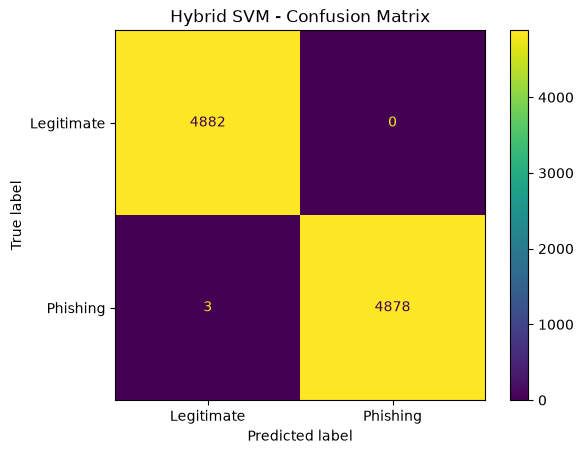

In [48]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_test, y_pred_hybrid)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Phishing"]
)

disp.plot()
plt.title("Hybrid SVM - Confusion Matrix")
plt.show()

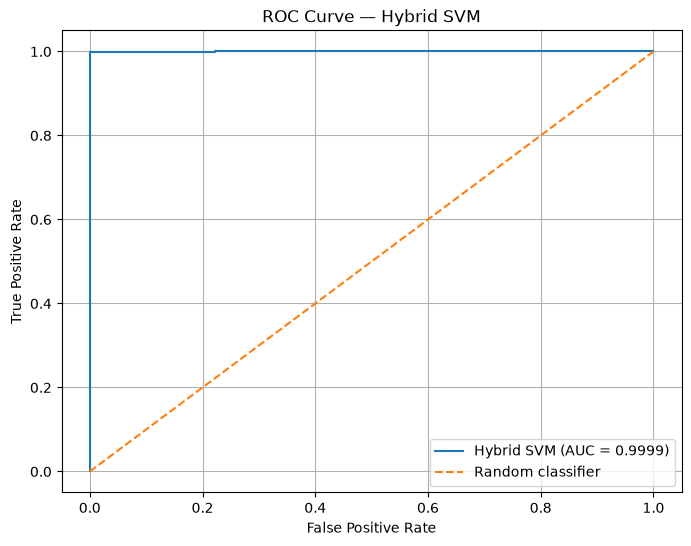

ROC-AUC: 0.9999


In [49]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_scores_hybrid
)

roc_auc = roc_auc_score(y_test, y_scores_hybrid)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Hybrid SVM (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Hybrid SVM")
plt.legend()
plt.grid(True)
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")

In [50]:
import pandas as pd

feature_names = [
    "url_length",
    "num_dots",
    "num_digits",
    "num_hyphens",
    "num_underscores",
    "num_slashes",
    "num_at",
    "num_question",
    "num_equal",
    "num_ampersand",
    "has_https",
    "has_ip",
    "num_subdomains",
    "entropy"
]

feature_summary = pd.DataFrame({
    "Feature": feature_names,
    "Description": [
        "Total length of the URL",
        "Number of dots",
        "Number of digits",
        "Number of hyphens",
        "Number of underscores",
        "Number of slashes",
        "Number of @ symbols",
        "Number of question marks",
        "Number of equals signs",
        "Number of ampersands",
        "Whether the URL uses HTTPS",
        "Whether the URL contains an IPv4-like address",
        "Estimated number of subdomains",
        "Character-distribution entropy"
    ]
})

display(feature_summary)

,Feature,Description
0,url_length,Total length of the URL
1,num_dots,Number of dots
2,num_digits,Number of digits
3,num_hyphens,Number of hyphens
4,num_underscores,Number of underscores
5,num_slashes,Number of slashes
6,num_at,Number of @ symbols
7,num_question,Number of question marks
8,num_equal,Number of equals signs
9,num_ampersand,Number of ampersands


,Legitimate (0),Phishing (1)
source,,
openphish,0,300
tranco,24406,0
urlhaus,0,24106


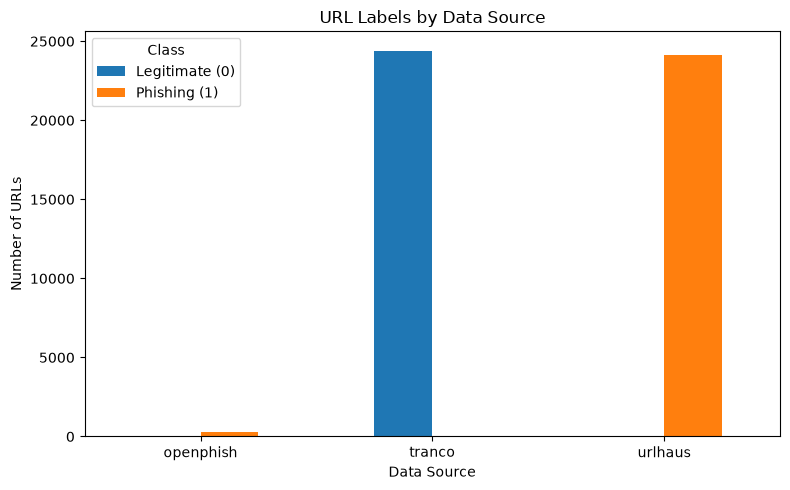

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

source_counts = pd.crosstab(
    df["source"],
    df["label"]
)

source_counts.columns = ["Legitimate (0)", "Phishing (1)"]

display(source_counts)

source_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("URL Labels by Data Source")
plt.xlabel("Data Source")
plt.ylabel("Number of URLs")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.tight_layout()
plt.show()

In [52]:
import joblib
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

model_path = model_dir / "hybrid_svm_model.joblib"

joblib.dump(best_hybrid_svm, model_path)

print("Hybrid SVM model saved successfully!")
print("Saved to:", model_path)

Hybrid SVM model saved successfully!
Saved to: models\hybrid_svm_model.joblib


In [53]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


In [54]:
print("Training URLs:", len(X_train))
print("Testing URLs:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training URLs: 39049
Testing URLs: 9763

Training labels:
label
1    19525
0    19524
Name: count, dtype: int64

Testing labels:
label
0    4882
1    4881
Name: count, dtype: int64


In [55]:
from tensorflow.keras.layers import TextVectorization

MAX_LENGTH = 200

url_vectorizer = TextVectorization(
    standardize=None,
    split="character",
    output_mode="int",
    output_sequence_length=MAX_LENGTH
)

# Learn the character vocabulary from training URLs only
url_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(
        X_train.astype(str).to_numpy()
    ).batch(1024)
)

# Convert URLs into sequences of character IDs
X_train_seq = url_vectorizer(
    X_train.astype(str).to_numpy()
)

X_test_seq = url_vectorizer(
    X_test.astype(str).to_numpy()
)

print("Training sequence shape:", X_train_seq.shape)
print("Testing sequence shape:", X_test_seq.shape)
print("Vocabulary size:", url_vectorizer.vocabulary_size())

39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
Training sequence shape: (39049, 200)
Testing sequence shape: (9763, 200)
Vocabulary size: 78


In [56]:
cnn_model = keras.Sequential([
    layers.Input(shape=(MAX_LENGTH,)),

    # Learn a vector representation of each character
    layers.Embedding(
        input_dim=url_vectorizer.vocabulary_size(),
        output_dim=32,
        mask_zero=False
    ),

    # Detect local character patterns
    layers.Conv1D(
        filters=64,
        kernel_size=5,
        activation="relu"
    ),

    # Summarize the detected patterns
    layers.GlobalMaxPooling1D(),

    # Reduce overfitting
    layers.Dropout(0.3),

    # Final binary classification
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 32)        │         2,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 196, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,913 (58.25 KB)

 Trainable params: 14,913 (58.25 KB)

 Non-trainable params: 0 (0.00 B)

In [57]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = cnn_model.fit(
    X_train_seq,
    y_train.to_numpy(),
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.9680 - loss: 0.0966 - val_accuracy: 0.9997 - val_loss: 0.0020
Epoch 2/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.9997 - loss: 0.0022 - val_accuracy: 0.9997 - val_loss: 0.0017
Epoch 3/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 12s 42ms/step - accuracy: 0.9998 - loss: 0.0017 - val_accuracy: 0.9997 - val_loss: 0.0016
Epoch 4/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 13s 48ms/step - accuracy: 0.9998 - loss: 0.0011 - val_accuracy: 0.9997 - val_loss: 0.0013
Epoch 5/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - accuracy: 0.9999 - loss: 9.9156e-04 - val_accuracy: 0.9997 - val_loss: 0.0010
Epoch 6/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - accuracy: 0.9999 - loss: 8.5966e-04 - val_accuracy: 0.9997 - val_loss: 8.6752e-04
Epoch 7/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.9999 - loss: 8.5950e-04 - val_accuracy: 0.9997 - val_loss: 4.7482e-04
Epoch 8/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - accuracy: 0.9999

In [58]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)
import numpy as np

# Predict phishing probabilities on the test set
y_prob_cnn = cnn_model.predict(X_test_seq, verbose=0).ravel()

# Convert probabilities to class predictions
y_pred_cnn = (y_prob_cnn >= 0.5).astype(int)

print("CNN Test Results")
print("-" * 35)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_cnn):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_cnn):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_cnn):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_cnn):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_cnn):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_cnn,
    target_names=["Legitimate", "Phishing"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_cnn))

CNN Test Results
-----------------------------------
Accuracy:  0.9997
Precision: 1.0000
Recall:    0.9994
F1-score:  0.9997
ROC-AUC:   0.9998

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      4882
    Phishing       1.00      1.00      1.00      4881

    accuracy                           1.00      9763
   macro avg       1.00      1.00      1.00      9763
weighted avg       1.00      1.00      1.00      9763

Confusion Matrix:
[[4882    0]
 [   3 4878]]


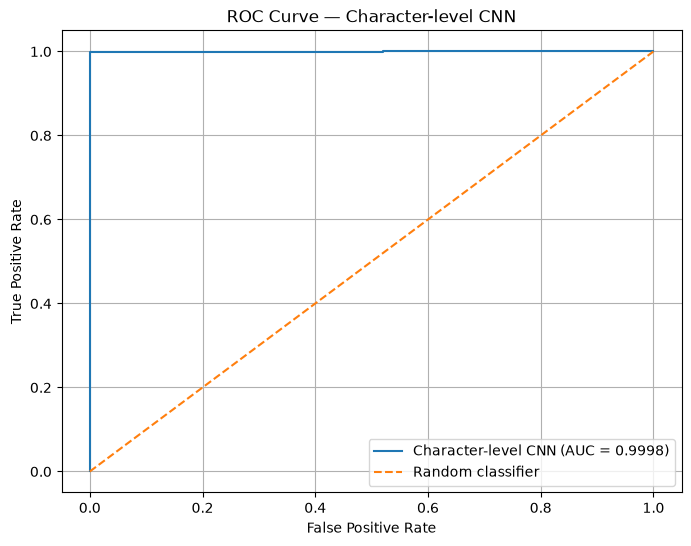

CNN ROC-AUC: 0.9998


In [59]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr_cnn, tpr_cnn, thresholds_cnn = roc_curve(
    y_test,
    y_prob_cnn
)

# Calculate AUC
auc_cnn = roc_auc_score(y_test, y_prob_cnn)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(
    fpr_cnn,
    tpr_cnn,
    label=f"Character-level CNN (AUC = {auc_cnn:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Character-level CNN")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"CNN ROC-AUC: {auc_cnn:.4f}")

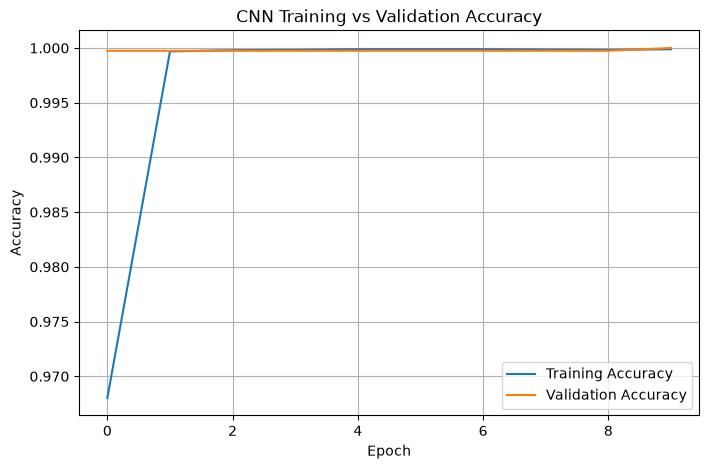

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

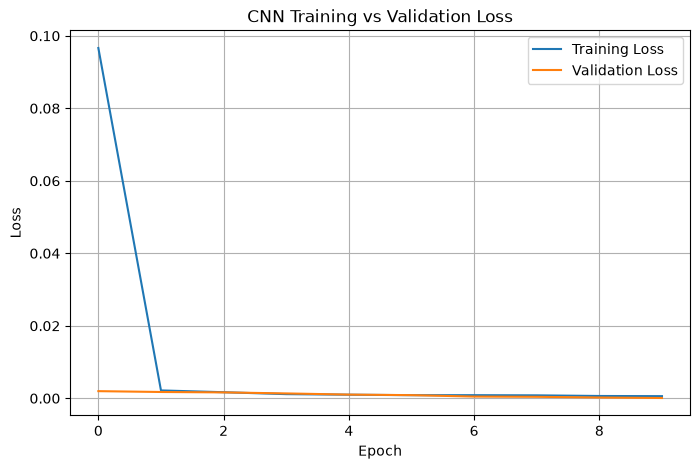

In [61]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [62]:
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

cnn_model_path = model_dir / "phishing_url_cnn.keras"

cnn_model.save(cnn_model_path)

print("CNN model saved successfully!")
print("Saved to:", cnn_model_path)

CNN model saved successfully!
Saved to: models\phishing_url_cnn.keras


In [63]:
import joblib
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

vectorizer_path = model_dir / "phishing_url_vectorizer.joblib"

joblib.dump(url_vectorizer, vectorizer_path)

print("Character vectorizer saved successfully!")
print("Saved to:", vectorizer_path)

Character vectorizer saved successfully!
Saved to: models\phishing_url_vectorizer.joblib


In [64]:
from pathlib import Path

model_dir = Path("models")

print("All project model files:")
for file in model_dir.iterdir():
    print("-", file.name)

print("\nModel files are saved locally in the models folder.")

All project model files:
- hybrid_svm_model.joblib
- phishing_url_cnn.keras
- phishing_url_vectorizer.joblib

Model files are saved locally in the models folder.
